# Precipitação e gravidade dos acidentes em rodovias federais de São Paulo

**ACH0042 — Resolução de Problemas II, USP/EACH**  
Gustavo Henrique Ferreira Alves, Gustavo Lima de Souza e Guilherme Padun Santos

O estudo avalia a associação entre a precipitação registrada por estações do INMET e a gravidade dos acidentes da PRF. As bases da PRF contêm uma linha por ocorrência e cobrem 2025 completo e janeiro a maio de 2026.

O desfecho tem três níveis ordenados — sem vítimas, com vítimas feridas e com vítimas fatais. A exposição é apresentada em duas escalas — precipitação horária em milímetros e presença de precipitação acima de zero.

A leitura começa pela cobertura e pelo pareamento, passa pela seleção dos acidentes e pela descrição da chuva, e termina com os modelos. As comparações descritivas mostram o que foi observado na amostra. As regressões respondem à pergunta sobre associação considerando a incerteza e, nos modelos ajustados, as covariáveis.

## 1. Dados produzidos pelo pipeline

Execute `python executar_pipeline.py` na raiz do projeto para gerar os CSVs seguindo o [README](README.md). Este notebook lê esses arquivos e apresenta resumos descritivos e estimativas já calculadas.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, MaxNLocator, MultipleLocator, PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.config import LIMITE_DISTANCIA_KM, LIMITE_TEMPO_MIN, PASTA_DADOS_PROCESSADOS
from src.modelos.preparacao import COVARIAVEIS_NECESSARIAS, calcular_fluxo_selecao

arquivos = {
    "prf": "acidentes_sp.csv",
    "inmet": "inmet_sp.csv",
    "integrada": "base_integrada.csv",
    "amostra": "base_modelagem.csv",
    "ordinal": "resultados_regressao_ordinal.csv",
    "multinomial": "resultados_regressao_multinomial.csv",
    "sensibilidade": "sensibilidade_distancia.csv",
    "ausencia": "diagnostico_ausencia_precipitacao.csv",
}
caminhos = {chave: PASTA_DADOS_PROCESSADOS / nome for chave, nome in arquivos.items()}
faltantes = [caminho.name for caminho in caminhos.values() if not caminho.is_file()]
if faltantes:
    raise FileNotFoundError(
        f"CSVs ausentes em datasets/processed/: {', '.join(faltantes)}. "
        "Execute python executar_pipeline.py na raiz do projeto."
    )

prf = pd.read_csv(
    caminhos["prf"],
    usecols=["ano", "data_inversa", "classificacao_acidente"],
    parse_dates=["data_inversa"],
)
inmet = pd.read_csv(caminhos["inmet"], usecols=["codigo_wmo"], dtype={"codigo_wmo": "string"})
integrada = pd.read_csv(
    caminhos["integrada"],
    usecols=[
        "status_integracao", "precipitacao_mm", "distancia_estacao_km", "diferenca_tempo_min",
        *COVARIAVEIS_NECESSARIAS,
    ],
)
amostra = pd.read_csv(
    caminhos["amostra"],
    usecols=["ano", "classificacao_acidente", "precipitacao_mm", "chuva_binaria"],
)
ordinal = pd.read_csv(caminhos["ordinal"])
multinomial = pd.read_csv(caminhos["multinomial"])
sensibilidade = pd.read_csv(caminhos["sensibilidade"])
ausencia = pd.read_csv(caminhos["ausencia"], index_col=0)

In [2]:
AZUL = "#27566D"
VERDE = "#28786B"
CINZA = "#5E6B6D"
GRADE = "#DFE8E4"
ROXO = "#78557C"
TEXTO = "#203530"
CLARO = "#E9F3EC"

gravidades = ["Sem Vítimas", "Com Vítimas Feridas", "Com Vítimas Fatais"]
rotulos_gravidade = ["Sem vítimas", "Vítimas feridas", "Vítimas fatais"]
cores_gravidade = [AZUL, VERDE, ROXO]
rotulos_periodo = {2025: "2025 · ano completo", 2026: "2026 · janeiro a maio"}

plt.rcParams.update({
    "font.size": 11,
    "text.color": TEXTO,
    "axes.labelcolor": TEXTO,
    "axes.titlecolor": TEXTO,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "grid.color": GRADE,
    "axes.axisbelow": True,
    "legend.frameon": False,
    "figure.dpi": 112,
    "figure.titlesize": 15,
    "figure.titleweight": "bold",
})


def inteiro(valor):
    return f"{valor:,.0f}".replace(",", ".")


def decimal(valor, casas=1):
    return f"{valor:.{casas}f}".replace(".", ",")


def barras_por_gravidade(ax, proporcoes, rotulos, limite, passo):
    posicoes = range(len(proporcoes))
    ax.barh(posicoes, proporcoes, color=cores_gravidade, height=0.54)
    for posicao, proporcao, rotulo in zip(posicoes, proporcoes, rotulos):
        ax.annotate(
            rotulo, (proporcao, posicao), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9,
        )
    ax.set_yticks(list(posicoes), rotulos_gravidade)
    ax.set(xlim=(0, limite), ylim=(len(proporcoes) - 0.5, -0.5))
    ax.xaxis.set_major_locator(MultipleLocator(passo))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x")


def exibir_estimativas(dados, rotulos, casas=4):
    tabela = dados[list(rotulos)].rename(columns=rotulos).copy()
    tabela["OR"] = dados["odds_ratio"].map(lambda valor: decimal(valor, casas))
    tabela["IC95%"] = [
        f"{decimal(inferior, casas)} a {decimal(superior, casas)}"
        for inferior, superior in zip(dados["ic_95_inf"], dados["ic_95_sup"])
    ]
    tabela["p"] = dados["p_valor"].map(lambda valor: decimal(valor, casas))
    display(tabela.reset_index(drop=True))

## 2. Cobertura dos dados

Antes de interpretar diferenças por ano, precisamos situar as janelas de observação. A tabela mostra as datas efetivamente cobertas e quantos acidentes tiveram uma medição de precipitação disponível após o pareamento.

In [3]:
periodos = prf.groupby("ano").agg(
    início=("data_inversa", "min"),
    fim=("data_inversa", "max"),
    acidentes=("data_inversa", "size"),
)
validos_por_ano = integrada.groupby("ano")["precipitacao_mm"].count()
cobertura = pd.DataFrame({
    "Início": periodos["início"].dt.strftime("%d/%m/%Y"),
    "Fim": periodos["fim"].dt.strftime("%d/%m/%Y"),
    "Acidentes PRF": periodos["acidentes"].map(inteiro),
    "Precipitação disponível": validos_por_ano.map(inteiro),
    "Disponibilidade": (validos_por_ano / periodos["acidentes"]).map(
        lambda valor: f"{decimal(valor * 100)}%"
    ),
})
cobertura.index.name = "Ano"

display(Markdown(
    f"**PRF:** {inteiro(len(prf))} acidentes. "
    f"**INMET:** {inteiro(len(inmet))} registros horários de "
    f"{inteiro(inmet['codigo_wmo'].nunique())} estações."
))
display(cobertura)

**PRF:** 6.515 acidentes. **INMET:** 583.680 registros horários de 40 estações.

,Início,Fim,Acidentes PRF,Precipitação disponível,Disponibilidade
Ano,,,,,
2025,01/01/2025,31/12/2025,4.683,3.982,"85,0%"
2026,01/01/2026,31/05/2026,1.832,1.679,"91,6%"


### Como a gravidade se distribui em cada período?

Esta leitura recupera a composição por ano da base da PRF. Cada painel usa como denominador o total de acidentes daquele período. Mostramos também as contagens para que o tamanho de cada categoria continue visível.

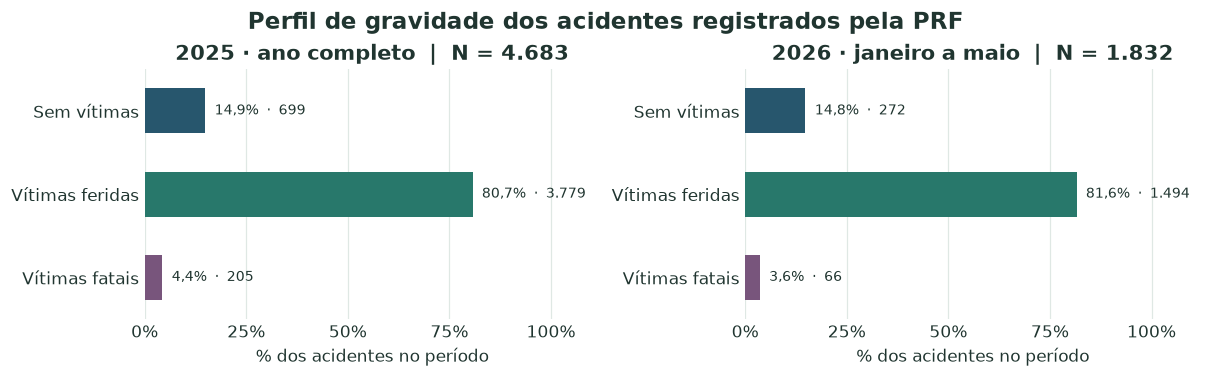

In [4]:
gravidade_por_ano = pd.crosstab(prf["ano"], prf["classificacao_acidente"]).reindex(columns=gravidades)

fig, eixos = plt.subplots(1, 2, figsize=(10.7, 3.25), layout="constrained")
fig.suptitle("Perfil de gravidade dos acidentes registrados pela PRF")
for ax, (ano, contagens) in zip(eixos, gravidade_por_ano.iterrows()):
    n = contagens.sum()
    proporcoes = contagens / n
    rotulos = [
        f"{decimal(proporcao * 100)}%  ·  {inteiro(qtd)}"
        for proporcao, qtd in zip(proporcoes, contagens)
    ]
    barras_por_gravidade(ax, proporcoes, rotulos, limite=1.12, passo=0.25)
    ax.set(title=f"{rotulos_periodo[ano]}  |  N = {inteiro(n)}", xlabel="% dos acidentes no período")
plt.show()

As barras representam a parcela de acidentes em cada nível de gravidade e o número ao lado é a contagem. Acidentes com vítimas feridas predominam em ambas as janelas, com 80,7% no ano completo de 2025 e 81,6% entre janeiro e maio de 2026. Casos fatais são a categoria menos frequente. Isso ajuda a antecipar o número menor de observações para as comparações que envolvem fatalidades. As janelas têm durações diferentes e a base reúne ocorrências registradas. As contagens descrevem a composição observada e não medem incidência anual.

## 3. Qualidade da integração PRF–INMET

A integração associa cada acidente à estação meteorológica mais próxima e, nessa estação, à medição mais próxima no tempo. Distância e diferença temporal ajudam a avaliar quão próxima é essa medida das condições no local e no horário do acidente.

### Onde se concentram as distâncias?

O histograma recupera a distribuição que aparecia no notebook antigo. Ele mostra se os pareamentos se concentram perto das estações e permite enxergar a cauda de distâncias maiores. Usamos todos os acidentes integrados com distância registrada, inclusive os que ficaram sem precipitação disponível.

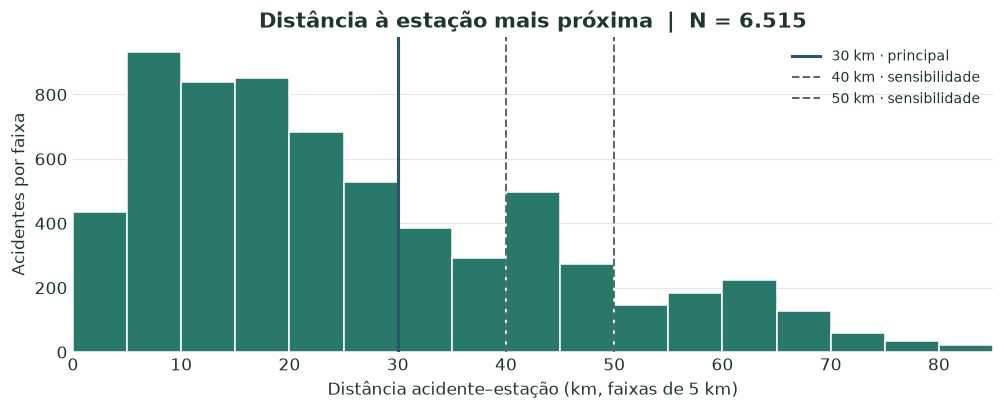

In [5]:
distancia = integrada["distancia_estacao_km"].dropna()
limites = sorted(sensibilidade["limite_km"].unique())

fig, ax = plt.subplots(figsize=(8.85, 3.55), layout="constrained")
faixas = range(0, int(distancia.max() // 5) * 5 + 6, 5)
ax.hist(distancia, bins=faixas, color=VERDE, edgecolor="white", linewidth=1)
for limite in limites:
    principal = limite == LIMITE_DISTANCIA_KM
    ax.axvline(
        limite, color=AZUL if principal else CINZA, linewidth=2 if principal else 1.3,
        linestyle="-" if principal else "--",
        label=f"{inteiro(limite)} km · {'principal' if principal else 'sensibilidade'}",
    )
ax.set(
    title=f"Distância à estação mais próxima  |  N = {inteiro(len(distancia))}",
    xlabel="Distância acidente–estação (km, faixas de 5 km)",
    ylabel="Acidentes por faixa",
    xlim=(0, faixas[-1]),
)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_major_locator(MaxNLocator(5, integer=True))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: inteiro(valor)))
ax.grid(axis="y")
ax.legend(loc="upper right", fontsize=9)
plt.show()

Cada barra conta os acidentes em uma faixa de 5 km. A faixa mais frequente está entre 5 e 10 km, e a mediana é 21,7 km. Há pareamentos acima de 80 km, mesmo após escolher a estação mais próxima. Essa cauda importa porque a medição de uma estação mais distante pode representar com menor precisão as condições no local do acidente. As três linhas marcam os limites usados na análise principal e na sensibilidade.

### Quanto da base fica dentro de cada limite?

A curva acumulada complementa o histograma. Ela permite ler a cobertura até cada distância e visualizar o ganho de cobertura ao aceitar pareamentos mais distantes.

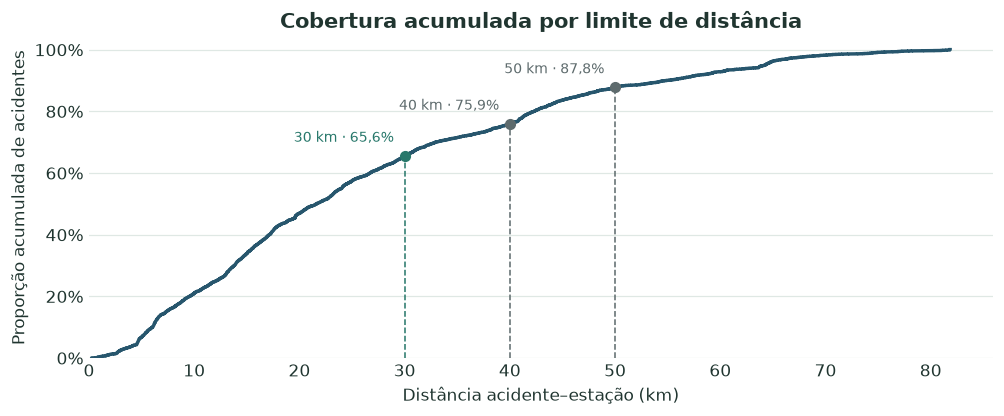

In [6]:
fig, ax = plt.subplots(figsize=(8.85, 3.6), layout="constrained")
ax.ecdf(distancia, color=AZUL, linewidth=2.2)
for limite in limites:
    proporcao = distancia.le(limite).mean()
    cor = VERDE if limite == LIMITE_DISTANCIA_KM else CINZA
    ax.vlines(limite, 0, proporcao, color=cor, linestyle="--", linewidth=1)
    ax.scatter(limite, proporcao, color=cor, s=38, zorder=3)
    ax.annotate(
        f"{inteiro(limite)} km · {decimal(proporcao * 100)}%",
        (limite, proporcao),
        xytext=(-7, 9),
        ha="right",
        textcoords="offset points",
        color=cor,
        fontsize=9,
    )

ax.set(
    title="Cobertura acumulada por limite de distância",
    xlabel="Distância acidente–estação (km)",
    ylabel="Proporção acumulada de acidentes",
    xlim=(0, None),
    ylim=(0, 1.04),
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y")
plt.show()

O valor na curva é a porcentagem de acidentes com distância menor ou igual ao limite. O corte de 30 km abrange 65,6% dos acidentes com distância registrada. A cobertura sobe para 75,9% a 40 km e 87,8% a 50 km. O ganho vem de aceitar estações mais distantes, por isso 40 e 50 km servem para avaliar sensibilidade e 30 km segue como análise principal. Esses percentuais incluem acidentes sem precipitação disponível. A tabela de seleção aplica os demais critérios e mostra quantos casos entram de fato na modelagem.

### Como se distribui a diferença de horário?

A mediana e o máximo resumem a diferença entre o horário registrado do acidente e o da medição pareada. Vale também observar a contagem em cada minuto para identificar concentrações que esses dois números não mostram.

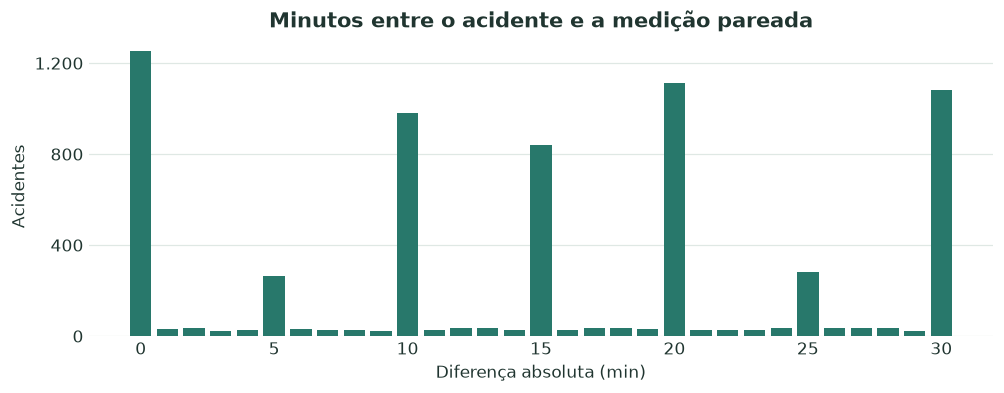

In [7]:
tempo = integrada["diferenca_tempo_min"].dropna()
contagem_tempo = tempo.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.85, 3.4), layout="constrained")
ax.bar(contagem_tempo.index, contagem_tempo, width=0.8, color=VERDE)
ax.set(
    title="Minutos entre o acidente e a medição pareada",
    xlabel="Diferença absoluta (min)",
    ylabel="Acidentes",
)
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_locator(MaxNLocator(4, integer=True))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: inteiro(valor)))
ax.grid(axis="y")
plt.show()

Cada barra indica quantos acidentes tiveram aquela diferença de horário. Há picos em 0, 10, 15, 20 e 30 minutos. A mediana é 15 minutos e o máximo, 30 minutos. A concentração em múltiplos de cinco é um padrão dos horários observados e, sozinha, não identifica sua origem. Como a maior diferença ficou abaixo do limite de 60 minutos, o critério temporal não eliminou acidentes adicionais na amostra principal.

### Precipitação ausente

Faltou medição de precipitação para 854 dos 6.515 acidentes (13,11%). O modelo ajustado de ausência do pipeline avalia se as chances de ficar sem medição diferem entre categorias de gravidade, considerando ano, mês, distância, condição meteorológica registrada pela PRF e estação do INMET. Acidentes com vítimas fatais são a referência na comparação de gravidade.

In [8]:
comparacoes_ausencia = ausencia.loc[ausencia.index.str.startswith("C(classificacao_acidente)[T.")].copy()
comparacoes_ausencia["Gravidade"] = (
    comparacoes_ausencia.index.str.extract(r"\[T\.(.+)\]", expand=False)
    + " vs. Com Vítimas Fatais"
)
exibir_estimativas(comparacoes_ausencia, {"Gravidade": "Comparação"})

,Comparação,OR,IC95%,p
0,Com Vítimas Feridas vs. Com Vítimas Fatais,"0,7262","0,4672 a 1,1287","0,1551"
1,Sem Vítimas vs. Com Vítimas Fatais,"0,9276","0,5671 a 1,5173","0,7648"


Os IC95% dos dois contrastes incluem 1. O diagnóstico não encontrou evidência estatisticamente significativa de associação entre gravidade e ausência de medição após o ajuste. Em MCAR, a probabilidade de ausência independe dos dados observados e não observados. Em MAR, essa probabilidade depende apenas de dados observados. Distinguir esses mecanismos exige pressupostos e evidências além dos contrastes de gravidade. A ausência permanece uma limitação, pois a regressão principal usa apenas casos com medição disponível.

## 4. Construção da amostra principal

A tabela usa a função de seleção do próprio pipeline sobre a base integrada. Separa a disponibilidade da precipitação dos critérios de distância, tempo e completude das covariáveis. Um registro de 0 mm conta como precipitação válida.

In [9]:
fluxo_oficial = calcular_fluxo_selecao(integrada, LIMITE_DISTANCIA_KM, LIMITE_TEMPO_MIN)
n_amostra = len(amostra)
if fluxo_oficial["registros_restantes"].iloc[-1] != n_amostra:
    raise ValueError("O fluxo de seleção difere da base de modelagem exportada. Verifique os CSVs.")

fluxo = pd.DataFrame({
    "Etapa": [
        "Base integrada",
        "Com precipitação válida",
        f"Dentro de {LIMITE_DISTANCIA_KM} km",
        f"Dentro de {LIMITE_TEMPO_MIN} min",
        "Com covariáveis completas",
    ],
    "Acidentes restantes": fluxo_oficial["registros_restantes"].map(inteiro),
    "Excluídos na etapa": fluxo_oficial["excluidos_etapa"].map(inteiro),
    "% da base integrada": fluxo_oficial["percentual_amostra_inicial"].map(
        lambda valor: f"{decimal(valor, 2)}%"
    ),
})
display(fluxo)

,Etapa,Acidentes restantes,Excluídos na etapa,% da base integrada
0,Base integrada,6.515,0,"100,00%"
1,Com precipitação válida,5.661,854,"86,89%"
2,Dentro de 30 km,3.730,1.931,"57,25%"
3,Dentro de 60 min,3.730,0,"57,25%"
4,Com covariáveis completas,3.730,0,"57,25%"


Leia cada linha como o conjunto restante após o critério indicado. Dos 6.515 acidentes, 5.661 tinham precipitação válida. O limite de 30 km excluiu outros 1.931, restando 3.730. A regra de 60 minutos e a exigência de covariáveis completas não produziram perdas adicionais. Os gráficos de chuva da próxima seção e os modelos principais referem-se a esses mesmos 3.730 acidentes.

## 5. Precipitação e gravidade na amostra principal

### Quanta chuva foi registrada quando choveu?

A presença de chuva e a intensidade entre medições positivas são aspectos diferentes da exposição. Na amostra principal, 3.328 de 3.730 acidentes tiveram registro de 0 mm (89,2%). Para examinar a assimetria da intensidade sem que essa massa em zero domine a figura, o histograma considera os 402 acidentes com precipitação positiva.

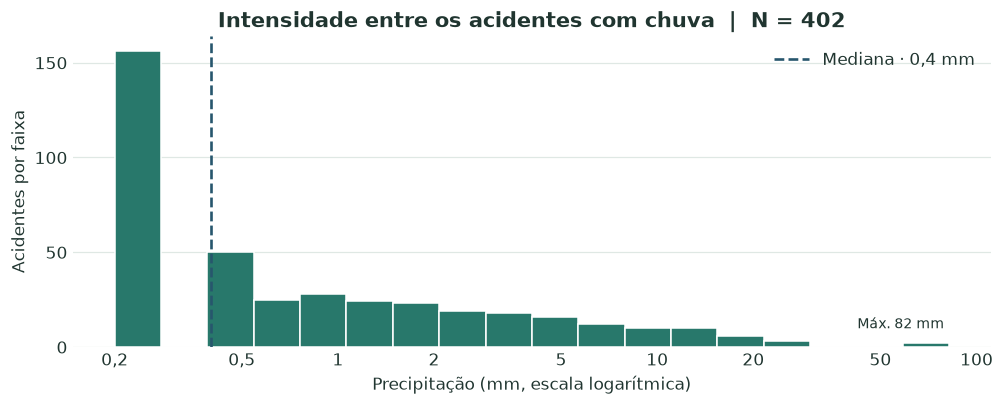

In [10]:
positiva = amostra.loc[amostra["precipitacao_mm"].gt(0), "precipitacao_mm"]
fig, ax = plt.subplots(figsize=(8.85, 3.5), layout="constrained")
faixas = np.geomspace(positiva.min(), positiva.max(), 19)
ax.hist(positiva, bins=faixas, color=VERDE, edgecolor="white", linewidth=1)
ax.axvline(
    positiva.median(), color=AZUL, linestyle="--", linewidth=1.7,
    label=f"Mediana · {decimal(positiva.median())} mm",
)
ax.set(
    title=f"Intensidade entre os acidentes com chuva  |  N = {inteiro(len(positiva))}",
    xlabel="Precipitação (mm, escala logarítmica)",
    ylabel="Acidentes por faixa",
    xscale="log",
)
ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}".replace(".", ",")))
ax.minorticks_off()
ax.yaxis.set_major_locator(MaxNLocator(4, integer=True))
ax.grid(axis="y")
ax.legend(loc="upper right")
ax.annotate(
    f"Máx. {decimal(positiva.max(), 0)} mm", (positiva.max(), 0),
    xytext=(-3, 12), textcoords="offset points", ha="right", fontsize=9,
)
plt.show()

Cada barra conta acidentes em uma faixa de largura constante na escala logarítmica. Assim, é possível ler as medições baixas e a cauda no mesmo gráfico. A mediana foi 0,4 mm, e 363 das 402 medições positivas (90,3%) foram de 6,0 mm ou menos. O gráfico inclui o máximo de 82 mm. A assimetria ajuda a entender por que comparar presença de chuva e usar a quantidade em milímetros são duas formas de resumir a exposição. A escala é uma escolha de apresentação e as regressões continuam usando os valores do pipeline.

### Com que frequência houve chuva em cada nível de gravidade?

Esta figura recupera a pergunta do notebook antigo na amostra principal. O denominador de cada barra é o total da respectiva categoria de gravidade. Os valores ao lado mostram a porcentagem e a contagem com chuva sobre o total da categoria.

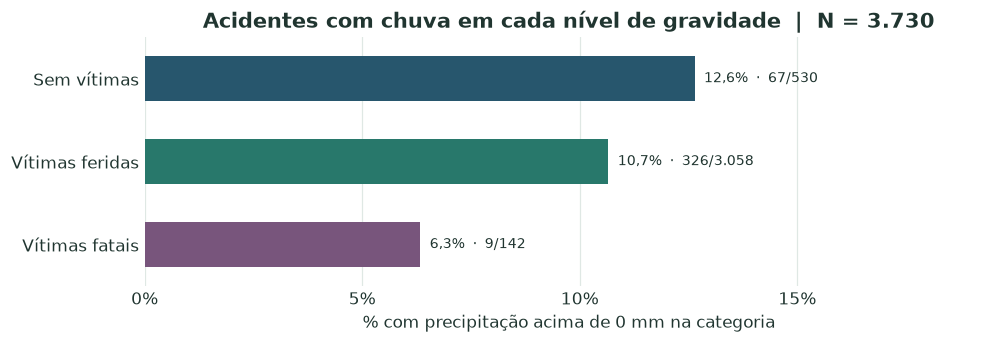

In [11]:
chuva_gravidade = (
    amostra.groupby("classificacao_acidente")["chuva_binaria"]
    .agg(com_chuva="sum", n="size").reindex(gravidades)
)
proporcoes = chuva_gravidade["com_chuva"] / chuva_gravidade["n"]
rotulos = [
    f"{decimal(proporcao * 100)}%  ·  {inteiro(chuva)}/{inteiro(n)}"
    for proporcao, chuva, n in zip(proporcoes, chuva_gravidade["com_chuva"], chuva_gravidade["n"])
]

fig, ax = plt.subplots(figsize=(8.85, 2.95), layout="constrained")
barras_por_gravidade(ax, proporcoes, rotulos, limite=0.195, passo=0.05)
ax.set(
    title=f"Acidentes com chuva em cada nível de gravidade  |  N = {inteiro(n_amostra)}",
    xlabel="% com precipitação acima de 0 mm na categoria",
)
plt.show()

Descritivamente, houve chuva em 12,6% dos acidentes sem vítimas, 10,7% dos acidentes com vítimas feridas e 6,3% dos fatais. Na última categoria, são nove acidentes com chuva entre 142. Mostrar o denominador ajuda a interpretar a diferença visual quando poucos casos influenciam a porcentagem. A regressão é a análise usada para avaliar a associação e sua incerteza, incluindo o ajuste pelas covariáveis.

### O perfil exploratório por período e gravidade

Estratificar por período ajuda a ver se os percentuais gerais escondem padrões distintos. Os dois painéis usam a mesma escala, e cada barra traz o número de acidentes com chuva e o total da célula. As janelas são 2025 completo e janeiro a maio de 2026.

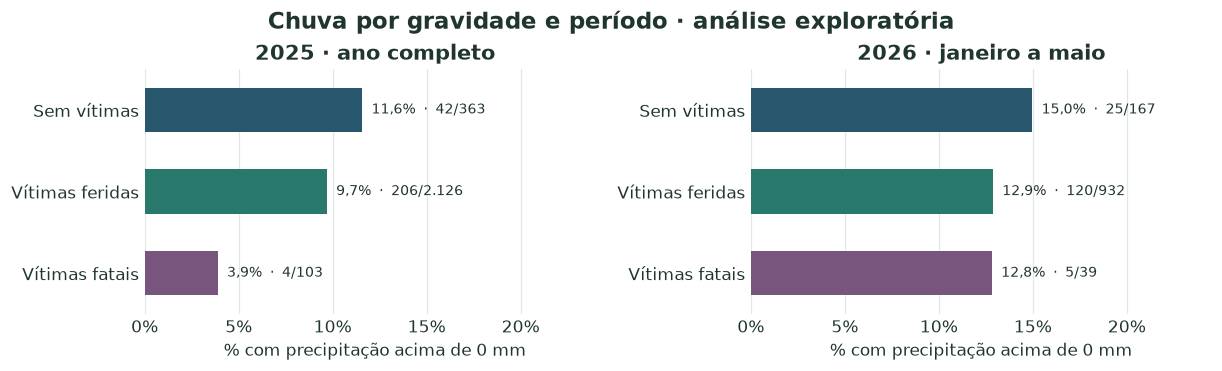

In [12]:
chuva_periodo = (
    amostra.groupby(["ano", "classificacao_acidente"])["chuva_binaria"]
    .agg(com_chuva="sum", n="size")
)
fig, eixos = plt.subplots(1, 2, figsize=(10.8, 3.2), layout="constrained")
fig.suptitle("Chuva por gravidade e período · análise exploratória")
for ax, (ano, grupo) in zip(eixos, chuva_periodo.groupby(level="ano")):
    contagens = grupo.droplevel("ano").reindex(gravidades)
    proporcoes = contagens["com_chuva"] / contagens["n"]
    rotulos = [
        f"{decimal(proporcao * 100)}%  ·  {inteiro(chuva)}/{inteiro(n)}"
        for proporcao, chuva, n in zip(proporcoes, contagens["com_chuva"], contagens["n"])
    ]
    barras_por_gravidade(ax, proporcoes, rotulos, limite=0.245, passo=0.05)
    ax.set(title=rotulos_periodo[ano], xlabel="% com precipitação acima de 0 mm")
plt.show()

Entre os acidentes fatais, houve 4 casos com chuva entre 103 acidentes em 2025 (ano completo) e 5 entre 39 acidentes de janeiro a maio de 2026. As porcentagens pareciam distantes, mas foram produzidas por poucos casos e por janelas que cobrem meses diferentes. A estratificação ajuda a localizar grupos pequenos e possíveis diferenças de composição. Ela é exploratória, sem ajuste para sazonalidade, distância ou demais covariáveis.

### Como se distribui a gravidade dentro de cada grupo de chuva?

Aqui o denominador muda. Para cada grupo de exposição, mostramos como se dividem os acidentes sem vítimas, com vítimas feridas e com vítimas fatais. A tabela mantém visíveis os tamanhos totais dos grupos e as contagens das categorias menores.

,Sem Vítimas,Com Vítimas Feridas,Com Vítimas Fatais,Total
Precipitação,,,,
Sem chuva,463,2.732,133,3.328
Com chuva,67,326,9,402


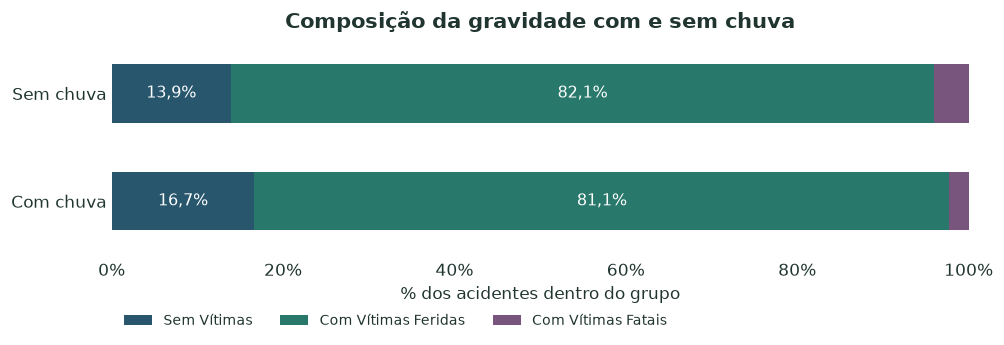

In [13]:
grupos = ["Sem chuva", "Com chuva"]
frequencias = pd.crosstab(amostra["chuva_binaria"], amostra["classificacao_acidente"])
frequencias = frequencias.reindex(index=[0, 1], columns=gravidades, fill_value=0)
frequencias.index = pd.Index(grupos, name="Precipitação")
frequencias.columns.name = None
totais = frequencias.sum(axis=1)
composicao = frequencias.div(totais, axis=0)
display(frequencias.assign(Total=totais).map(inteiro))

fig, ax = plt.subplots(figsize=(8.85, 2.95), layout="constrained")
acumulado = pd.Series(0.0, index=grupos)
for gravidade, cor in zip(gravidades, cores_gravidade):
    valores = composicao[gravidade]
    ax.barh(grupos, valores, left=acumulado, height=0.54, color=cor, label=gravidade)
    for linha, grupo in enumerate(grupos):
        if valores.loc[grupo] >= 0.08:
            ax.text(
                acumulado.loc[grupo] + valores.loc[grupo] / 2, linha,
                f"{decimal(valores.loc[grupo] * 100)}%",
                ha="center", va="center", color="white", fontsize=10,
            )
    acumulado += valores

ax.set(
    title="Composição da gravidade com e sem chuva",
    xlabel="% dos acidentes dentro do grupo",
    xlim=(0, 1), ylim=(1.52, -0.52),
)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncols=3, fontsize=9)
plt.show()

Cada faixa colorida é uma parcela da barra de 100%. Acidentes com vítimas feridas representam cerca de quatro quintos das ocorrências em ambos os grupos. Os casos fatais foram 9 de 402 com chuva (2,2%) e 133 de 3.328 sem chuva (4,0%). O gráfico descreve a composição dos acidentes observados e ajuda a interpretar o contraste bruto. A base não traz o volume de tráfego para medir o risco de sofrer um acidente, e a comparação visual não incorpora o ajuste.

## 6. Regressão logística ordinal

Vimos diferenças descritivas entre grupos. A regressão estima a associação com a gravidade e permite comparar os resultados com e sem ajuste por fase do dia, tipo de pista, traçado da via, ano e mês. A escala do desfecho é ordenada e a razão de chances (OR) se refere às chances cumulativas de ficar acima de um corte da gravidade.

A exposição contínua corresponde a um acréscimo de 1 mm. A binária compara presença de chuva com 0 mm. A tabela apresenta OR, IC95% e p com seis casas decimais. Cada painel usa sua própria escala horizontal.

,Exposição,Modelo,OR,IC95%,p
0,Precipitação (por 1 mm),Bruto,"0,977537","0,949680 a 1,006212","0,123520"
1,Chuva (presença vs. 0 mm),Bruto,"0,765912","0,592193 a 0,990591","0,042154"
2,Precipitação (por 1 mm),Ajustado,"0,977261","0,949118 a 1,006238","0,122871"
3,Chuva (presença vs. 0 mm),Ajustado,"0,831317","0,637730 a 1,083667","0,171971"


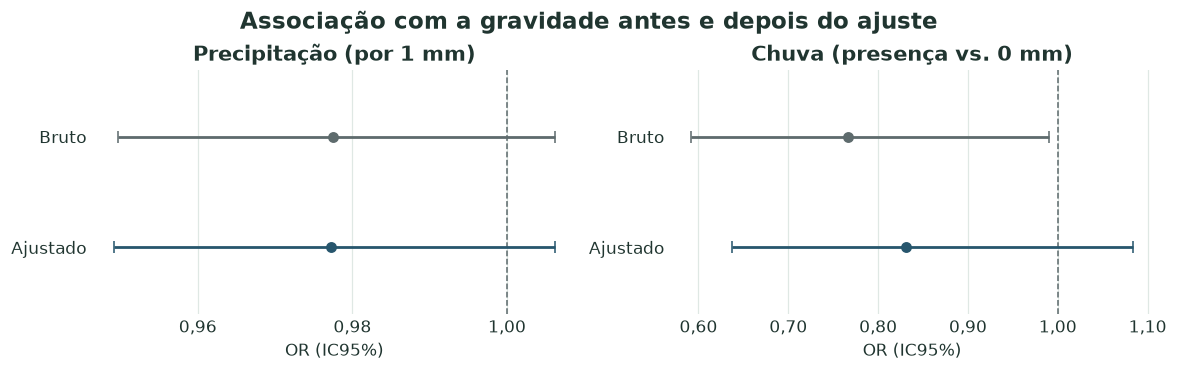

In [14]:
exposicoes = {
    "precipitacao_mm": "Precipitação (por 1 mm)",
    "chuva_binaria": "Chuva (presença vs. 0 mm)",
}
efeitos_ordinais = ordinal.loc[ordinal["variavel"].isin(exposicoes)].copy()
efeitos_ordinais["Exposição"] = efeitos_ordinais["variavel"].map(exposicoes)
efeitos_ordinais["Modelo"] = efeitos_ordinais["modelo"].str.extract(r" - (Bruto|Ajustado) -")
exibir_estimativas(efeitos_ordinais, {"Exposição": "Exposição", "Modelo": "Modelo"}, casas=6)

fig, eixos = plt.subplots(1, 2, figsize=(10.4, 3.2), layout="constrained")
fig.suptitle("Associação com a gravidade antes e depois do ajuste")
for ax, (variavel, titulo) in zip(eixos, exposicoes.items()):
    efeitos = efeitos_ordinais.loc[efeitos_ordinais["variavel"].eq(variavel)].set_index("Modelo")
    ax.axvline(1, color=CINZA, linestyle="--", linewidth=1)
    for posicao, (modelo, cor) in enumerate((("Bruto", CINZA), ("Ajustado", AZUL))):
        efeito = efeitos.loc[modelo]
        or_estimado = efeito["odds_ratio"]
        ax.errorbar(
            or_estimado, posicao,
            xerr=[[or_estimado - efeito["ic_95_inf"]], [efeito["ic_95_sup"] - or_estimado]],
            fmt="o", color=cor, capsize=4, linewidth=1.8, markersize=6,
        )
    ax.set(title=titulo, xlabel="OR (IC95%)", ylim=(1.6, -0.6))
    ax.set_yticks([0, 1], ["Bruto", "Ajustado"])
    ax.xaxis.set_major_locator(MultipleLocator(0.02 if variavel == "precipitacao_mm" else 0.1))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: decimal(valor, 2)))
    ax.grid(axis="x")

plt.show()

O ponto é a OR estimada e o traço horizontal é o IC95%. A linha vertical marca OR = 1, referência para ausência de associação na escala do modelo. Na análise bruta, o intervalo para chuva binária ficou abaixo de 1. Com o ajuste, a OR binária passou de 0,766 para 0,831, e os intervalos de ambas as exposições incluíram 1. Os modelos ajustados da análise principal não forneceram evidência estatisticamente significativa de associação entre precipitação e gravidade. A amplitude dos intervalos indica a incerteza que permanece, sobretudo para a comparação presença de chuva versus 0 mm.

## 7. Diagnóstico exploratório de chances proporcionais

A regressão ordinal estima uma associação comum aos cortes cumulativos da escala. O pipeline também compara, de forma exploratória, os coeficientes de dois cortes. O primeiro contrasta acidentes com alguma vítima e acidentes sem vítimas. O segundo contrasta acidentes fatais e as demais categorias. O diagnóstico sugeriu diferenças entre os coeficientes dos cortes. Ele orienta a leitura da estimativa ordinal como resumo e deve ser interpretado como exploratório. Um teste formal de Brant exigiria um procedimento separado.

## 8. Regressão logística multinomial complementar

A regressão ordinal é a análise principal porque aproveita a ordem da gravidade. A multinomial permite estimar associações separadas para acidentes com vítimas feridas e fatais, ambos em relação a acidentes sem vítimas. Ela dispensa a hipótese de chances proporcionais e ajuda a avaliar se os contrastes específicos contam uma história diferente da estimativa ordinal comum.

In [15]:
efeitos_multinomiais = multinomial.assign(
    Exposição=multinomial["variavel"].map(exposicoes),
)
exibir_estimativas(efeitos_multinomiais, {"Exposição": "Exposição", "comparacao": "Comparação"})

,Exposição,Comparação,OR,IC95%,p
0,Precipitação (por 1 mm),Com Vítimas Feridas vs Sem Vítimas,"0,9731","0,9442 a 1,0028","0,0754"
1,Precipitação (por 1 mm),Com Vítimas Fatais vs Sem Vítimas,"0,9888","0,9243 a 1,0579","0,7438"
2,Chuva (presença vs. 0 mm),Com Vítimas Feridas vs Sem Vítimas,"0,8990","0,6715 a 1,2035","0,4742"
3,Chuva (presença vs. 0 mm),Com Vítimas Fatais vs Sem Vítimas,"0,5544","0,2651 a 1,1590","0,1169"


Cada linha compara uma categoria à referência sem vítimas. Os quatro IC95% incluem 1 e os contrastes de fatalidade são menos precisos que os de feridos. Por exemplo, para chuva binária a OR estimada de fatalidade versus sem vítimas é 0,554, com IC95% de 0,265 a 1,159. A amplitude comporta associações em direções distintas. A análise complementar, portanto, oferece contexto para a interpretação do modelo principal, especialmente na categoria com poucos casos fatais com chuva.

## 9. Sensibilidade ao limite de distância

Ampliar o limite espacial aumenta a amostra e inclui acidentes vinculados a estações mais distantes. A finalidade desta análise é verificar como as estimativas ajustadas se comportam quando se aceitam esses pareamentos. O cenário principal de 30 km aparece destacado e o eixo de cada painel mostra o N usado em cada cenário.

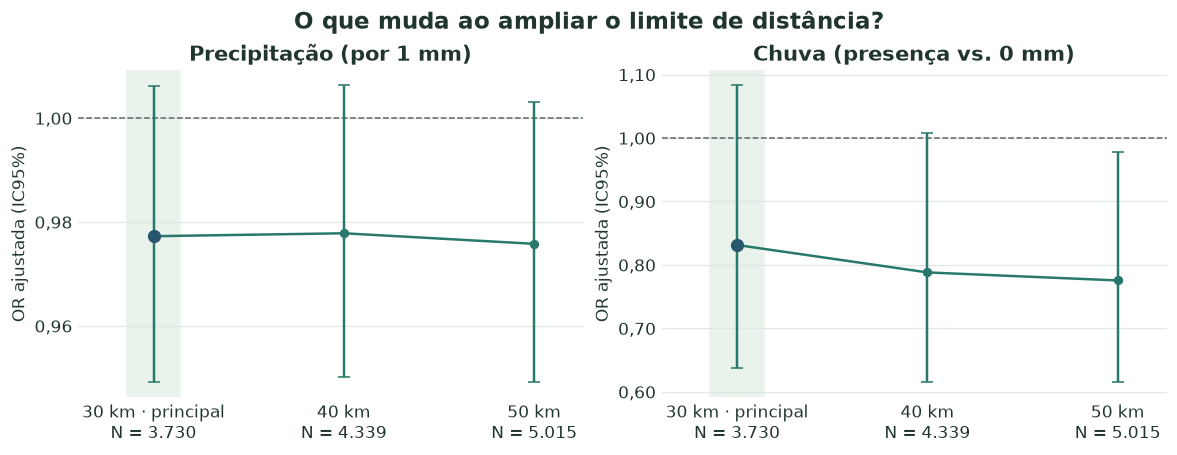

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(10.4, 3.95), layout="constrained")
fig.suptitle("O que muda ao ampliar o limite de distância?")
for ax, (exposicao, titulo) in zip(eixos, exposicoes.items()):
    efeitos = sensibilidade.loc[sensibilidade["exposicao"].eq(exposicao)].sort_values("limite_km")
    x = efeitos["limite_km"]
    y = efeitos["odds_ratio"]
    ax.axvspan(LIMITE_DISTANCIA_KM - 1.4, LIMITE_DISTANCIA_KM + 1.4, color=CLARO, zorder=0)
    ax.axhline(1, color=CINZA, linestyle="--", linewidth=1)
    ax.errorbar(
        x, y,
        yerr=[y - efeitos["ic_95_inf"], efeitos["ic_95_sup"] - y],
        fmt="o-", color=VERDE, capsize=4, linewidth=1.6, markersize=5,
    )
    principal = efeitos["limite_km"].eq(LIMITE_DISTANCIA_KM)
    ax.scatter(x[principal], y[principal], color=AZUL, s=56, zorder=4)
    ax.set_xticks(x, [
        f"{inteiro(limite)} km" + (" · principal" if limite == LIMITE_DISTANCIA_KM else "") + f"\nN = {inteiro(n)}"
        for limite, n in zip(x, efeitos["n"])
    ])
    ax.set(title=titulo, ylabel="OR ajustada (IC95%)")
    ax.yaxis.set_major_locator(MultipleLocator(0.02 if exposicao == "precipitacao_mm" else 0.1))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: decimal(valor, 2)))
    ax.grid(axis="y")
    ax.margins(x=0.12)

plt.show()

Os pontos são as OR ajustadas, as barras verticais são os IC95% e a linha tracejada marca OR = 1. A amostra passa de 3.730 a 4.339 e 5.015 acidentes. Por 1 mm, as estimativas ficaram próximas de 0,98 e os três intervalos incluíram 1. Para chuva binária, a OR foi de 0,831 a 30 km para 0,775 a 50 km, quando o intervalo ficou abaixo de 1. Isso indica maior sensibilidade ao limite para a exposição binária. Ao ampliar o limite, mudam tanto o tamanho quanto a composição da amostra. A conclusão principal continua baseada nos 30 km predefinidos.

## 10. Síntese e limitações

Na amostra principal de até 30 km, os modelos ajustados não forneceram evidência estatisticamente significativa de associação entre precipitação e gravidade. A análise de sensibilidade mostrou estimativas semelhantes para a exposição contínua e maior variação para a presença de chuva.

A precipitação é uma medida da estação pareada, sujeita à distância e à diferença de horário em relação ao acidente. Casos sem medição não entram nos modelos ordinais. Como a base reúne acidentes registrados, os resultados descrevem a gravidade entre essas ocorrências. O risco de ocorrer um acidente exigiria dados de exposição ao tráfego.